# 缺陷 CNOT：从 patch 重构到完整线路与纠错实验

本 Notebook 调用 `defective_cnot_d3` 已有函数，**实际生成完整物理 Stim CNOT 并执行解码实验**。案例固定为原始 d=3、C/A/T 三个 patch，以及控制中心数据比特 (3,11) 永久失效。允许距离下降，明确报告静态距离和完整 DEM 故障距离。

建议先了解 surface code 的 stabilizer、gauge、lattice surgery 和 Pauli frame。选择 **“Conda defective-cnot-d3 (Python 3.12)”** 内核，再按顺序运行，或使用 **Restart Kernel and Run All**。完整运行不依赖旧输出或隐藏变量。

流程：环境与参数 → 缺陷 patch/gauges → 完整 CNOT 与各阶段 → frame/flow 与无噪声验证 → 电路噪声与 DEM → 距离 → PyMatching 采样 → 导出与图表 → 独立 TQEC 参考 → 交付复核。

默认每组 100,000 shots，共 12 组。所有新产物写入独立的 `notebook_runs/<时间戳>/`；已有 `results/` 保留。主线路仅含局域物理门；理想 Choi harness 是单独的验证文件，不参与噪声和性能统计。


## 1. 定位实验目录并检查内核

支持从本目录或工作区根目录启动。先定位已有模块，再导入 `patches`，让 TQEC、Matplotlib 等缓存落在项目内。错误内核会在此给出明确提示。


In [1]:
from pathlib import Path
import os, sys, json, math, hashlib, itertools, subprocess, html
from collections import Counter
from datetime import datetime, timezone
import importlib.metadata as metadata

EXPERIMENT_DIR = None
for root in (Path.cwd(), *Path.cwd().parents):
    for candidate in (root, root / '实验代码' / 'defective_cnot_d3'):
        if (candidate / 'circuit_builder.py').is_file() and (candidate / 'patches.py').is_file():
            EXPERIMENT_DIR = candidate.resolve()
            break
    if EXPERIMENT_DIR is not None:
        break
if EXPERIMENT_DIR is None:
    raise RuntimeError('请从 defective_cnot_d3 或其工作区根目录启动 Notebook。')
sys.path.insert(0, str(EXPERIMENT_DIR))
assert sys.version_info[:2] == (3, 12), '请选择 Conda defective-cnot-d3 的 Python 3.12 内核。'
EXPECTED_PREFIX = (EXPERIMENT_DIR / '.conda' / 'envs' / 'defective-cnot-d3').resolve()
assert Path(sys.prefix).resolve() == EXPECTED_PREFIX, '请选择本项目的 Conda defective-cnot-d3 内核，勿使用旧环境或 base。'
assert (EXPECTED_PREFIX / 'conda-meta' / 'history').is_file(), '当前目录不是 Conda 环境。'

try:
    import patches  # 在导入 TQEC/绘图模块前设置本地缓存
    import numpy as np
    import stim, pymatching
    from IPython.display import display, HTML, Image, Markdown
    from patches import build_patches, DEAD
    from circuit_builder import build_cnot
    from measurement_relations import bits
    from analysis import add_noise, distance_audit, sample_decode, low_weight_distance
    from run_experiment import validate_noiseless, export_experiment, export_patches, write_json
    from prepare_sources import tree_hash
except ImportError as error:
    raise RuntimeError('当前内核缺少实验依赖；请使用 README 中的项目环境和 Notebook 安装命令。') from error

def show_table(rows):
    if not rows:
        return
    columns = list(rows[0])
    head = ''.join('<th>'+html.escape(str(c))+'</th>' for c in columns)
    body = ''.join('<tr>'+''.join('<td>'+html.escape(str(row[c]))+'</td>' for c in columns)+'</tr>' for row in rows)
    display(HTML('<table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'))

print('实验目录:', EXPERIMENT_DIR)
print('内核 Python:', sys.executable)
print('Conda prefix:', sys.prefix)
show_table([{'依赖': p, '版本': metadata.version(p)} for p in ('numpy','stim','pymatching','tqec','nbformat','ipykernel')])


实验目录: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3
内核 Python: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\.conda\envs\defective-cnot-d3\python.exe
Conda prefix: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\.conda\envs\defective-cnot-d3


依赖,版本
numpy,1.26.4
stim,1.16.0
pymatching,2.4.0
tqec,0.2.0
nbformat,5.11.1
ipykernel,7.4.0


## 2. 设置参数并核验固定来源

此单元是主要配置入口。修改 `SHOTS` 可进行快速试跑；`SHOTS=100_000` 对应完整实验。缺陷位置和六轮时序保持已确认的设计。源码指纹不匹配时先停止，避免混用其他版本。


In [2]:
SHOTS = 100_000
PROBABILITIES = (1e-4, 1e-3, 3e-3)
SEED = 20261013
NOISELESS_SHOTS = 1024
assert SHOTS > 0
assert all(0 < p < 1 for p in PROBABILITIES)

SOURCES = json.loads((EXPERIMENT_DIR / 'sources.json').read_text(encoding='utf-8'))
snl_source = EXPERIMENT_DIR / 'third_party' / 'snl'
assert tree_hash(snl_source, SOURCES['snl_files']) == SOURCES['snl_tree_sha256']
assert hashlib.sha256((EXPERIMENT_DIR / 'third_party' / 'snl.zip').read_bytes()).hexdigest() == SOURCES['snl_archive_sha256']
TQEC_SOURCE = Path(os.environ.get('DEFECTIVE_CNOT_TQEC_SOURCE', EXPERIMENT_DIR.parents[1] / '.runtime' / 'tqec-source'))
assert tree_hash(TQEC_SOURCE, SOURCES['tqec_files']) == SOURCES['tqec_tree_sha256']

RUN_DIR = EXPERIMENT_DIR / 'notebook_runs' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
CONFIG = {
    'nominal_distance': 3,
    'defect': {'patch': 'C', 'global': list(DEAD), 'local': [3,3], 'kind': 'permanent data qubit'},
    'stage_rounds': 6, 'shots_per_group': SHOTS, 'probabilities': list(PROBABILITIES),
    'seed_base': SEED, 'seed_formula': 'seed_base + 100*case_index + 10*basis_index + p_index',
    'noise': {'R':'X_ERROR(p) after reset', 'M':'M(p)', 'H,X,Z':'DEPOLARIZE1(p)',
              'CX':'DEPOLARIZE2(p)', 'idle':'DEPOLARIZE1(p) on active healthy data at idle TICK'},
    'python': sys.version.split()[0],
    'environment_kind': 'conda', 'environment_prefix': sys.prefix,
    'versions': {p:metadata.version(p) for p in ('numpy','stim','pymatching','tqec','tqecd','matplotlib')},
    'sources': SOURCES,
}
write_json(RUN_DIR / 'config.json', CONFIG)
print('源码指纹通过；本次输出:', RUN_DIR)
print('计划采样:', 2 * 2 * len(PROBABILITIES) * SHOTS, 'shots')


源码指纹通过；本次输出: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\notebook_runs\20261015T062709_817016Z
计划采样: 1200000 shots


## 3. 重构含缺陷 patch，并独立检查静态距离

调用 `build_patches(True)` 使用 SnL 的固定窗口策略。控制窗口的数据数应从 9 降为 8，(3,11) 必须被排除；C、CA 有 gauge 自由度。`audit()` 校验逻辑代数，并用独立最小权重动态规划交叉验证 SnL 距离。

CA/AT 是合并期间启用的长矩形 patch，初始 C/A/T 窗口保持 3×3。


In [3]:
PATCHES = {'healthy': build_patches(False), 'defective': build_patches(True)}
patch_rows = []
for case, stage_patches in PATCHES.items():
    for name, patch in stage_patches.items():
        audit = patch.audit()
        assert audit['algebra_distances'] == patch.distances
        patch_rows.append({'案例':case, 'patch':name, '数据数':len(patch.data),
                           '逻辑数':audit['logical_qubits'], 'gauge数':audit['gauge_qubits'],
                           'd_X':patch.distances['X'], 'd_Z':patch.distances['Z']})
assert DEAD not in PATCHES['defective']['C'].data
assert len(PATCHES['defective']['C'].data) == 8
assert PATCHES['defective']['C'].distances == {'X':2,'Z':2}
show_table(patch_rows)


Found 1 defect clusters.
Found 1 defect clusters.


案例,patch,数据数,逻辑数,gauge数,d_X,d_Z
healthy,C,9,1,0,3,3
healthy,A,9,1,0,3,3
healthy,T,9,1,0,3,3
healthy,CA,21,1,0,7,3
healthy,AT,21,1,0,3,7
defective,C,8,1,1,2,2
defective,A,9,1,0,3,3
defective,T,9,1,0,3,3
defective,CA,20,1,1,6,2
defective,AT,21,1,0,3,7


### 3.1 查看 gauges 和 super-stabilizers

中心缺陷附近形成四个 weight-3 gauges；同类型的两个 gauges 相乘形成 weight-6 super-stabilizer。单个 gauge outcome 可以随机，不能直接当成确定性 detector。


In [4]:
control_patch = PATCHES['defective']['C']
show_table([{'类型':c.basis, '辅助坐标':c.ancilla, '权重':len(c.data), '数据支持':c.data}
            for c in control_patch.checks if c.gauge])
show_table([{'类型':basis, '权重':len(data), '数据支持':data}
            for basis,data in control_patch.stabilizers if len(data)==6])
show_table([{'round':r, 'gauge相位':'X' if r%2==0 else 'Z',
            '本轮gauge数':sum(c.gauge for c in control_patch.round_checks(r)),
            '本轮checks总数':len(control_patch.round_checks(r))} for r in range(6)])


类型,辅助坐标,权重,数据支持
X,"(4, 10)",3,"((3, 9), (5, 9), (5, 11))"
X,"(2, 12)",3,"((1, 11), (1, 13), (3, 13))"
Z,"(4, 12)",3,"((3, 13), (5, 11), (5, 13))"
Z,"(2, 10)",3,"((1, 9), (1, 11), (3, 9))"


类型,权重,数据支持
X,6,"((1, 11), (1, 13), (3, 9), (3, 13), (5, 9), (5, 11))"
Z,6,"((1, 9), (1, 11), (3, 9), (3, 13), (5, 11), (5, 13))"


round,gauge相位,本轮gauge数,本轮checks总数
0,X,2,6
1,Z,2,6
2,X,2,6
3,Z,2,6
4,X,2,6
5,Z,2,6


## 4. 生成完整物理 CNOT

调用已有 `build_cnot` 串接整个协议，自动计算跨阶段测量关系和 Pauli frame。分别生成 X/Z 读出，以及同几何同时序的健康对照。下面五个单元逐段检查生成器实际安排的操作，使用同一个已生成线路；不复制或另写 CNOT 算法。


In [5]:
EXPERIMENTS = {}
for case, defective in (('healthy',False),('defective',True)):
    for basis in 'XZ':
        EXPERIMENTS[case,basis] = build_cnot(defective, (basis,basis), basis)
exp = EXPERIMENTS['defective','Z']
assert exp.hardware_audit() == {'dead_qubit_operations':0,'two_qubit_edges_local':True,'moment_conflicts':0}
assert 'MPP' not in {instruction.name for instruction in exp.circuit}
show_table([{'案例':case,'读出':basis,'器件数':e.circuit.num_qubits,'TICK':e.circuit.num_ticks,
            '测量数':e.circuit.num_measurements,'detector数':e.circuit.num_detectors,
            'observable数':e.circuit.num_observables} for (case,basis),e in EXPERIMENTS.items()])

def show_stage(experiment, stage):
    operations = [op for op in experiment.operations if op['stage']==stage]
    counts = Counter(op['name'] for op in operations)
    records = [r for r in experiment.records if r['stage']==stage]
    show_table([{'阶段':stage,'TICK数':counts['TICK'],'物理测量数':len(records),
                '绝对测量编号范围':(records[0]['index'],records[-1]['index']) if records else None,
                '操作批次数':dict(counts)}])
    print('首个非 TICK 操作:',next(op for op in operations if op['name']!='TICK'))


案例,读出,器件数,TICK,测量数,detector数,observable数
healthy,X,65,252,801,760,2
healthy,Z,65,251,801,760,2
defective,X,64,252,740,671,2
defective,Z,64,251,740,671,2


### 4.1 准备 C、A、T，并稳定校验六轮

本 Z 基实验准备 C/T 的逻辑 0；A 准备逻辑 +。X 基实验改为准备 C/T 的逻辑 +。初始化后运行六轮校验，X/Z gauges 交替。


In [6]:
show_stage(exp, 'prepare')


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
prepare,51,132,"(0, 131)","{'R': 7, 'TICK': 51, 'H': 13, 'CX': 24, 'M': 6}"


首个非 TICK 操作: {'name': 'R', 'targets': [7, 8, 9, 21, 22, 34, 35, 36, 3, 4, 5, 17, 18, 19, 30, 31, 32, 48, 49, 50, 54, 55, 56, 60, 61, 62], 'stage': 'prepare', 'round': -1}


### 4.2 ZZ merge：C 与 A 合并

在 y=7 routing 行准备 X 正本征态，用 CA+T 的 checks 测量六轮，建立 Z_C Z_A 关联。失效位置和其关联边继续禁用。


In [7]:
route_ca = set(PATCHES['defective']['CA'].data) - set(PATCHES['defective']['C'].data) - set(PATCHES['defective']['A'].data)
print('CA routing 数据:',sorted(route_ca))
show_stage(exp, 'zz_merge')


CA routing 数据: [(1, 7), (3, 7), (5, 7)]


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
zz_merge,50,156,"(132, 287)","{'R': 7, 'TICK': 50, 'H': 13, 'CX': 24, 'M': 6}"


首个非 TICK 操作: {'name': 'R', 'targets': [6, 20, 33], 'stage': 'zz_merge', 'round': 5}


### 4.3 ZZ split：恢复分离 C/A

以 X 读出 CA routing 数据，然后恢复 C/A/T 六轮 checks。保留 routing 测量与跨阶段 gauge parity，这些结果参与 split frame。


In [8]:
show_stage(exp, 'zz_split')


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
zz_split,50,135,"(288, 422)","{'H': 13, 'TICK': 50, 'M': 7, 'R': 6, 'CX': 24}"


首个非 TICK 操作: {'name': 'H', 'targets': [6, 20, 33], 'stage': 'zz_split', 'round': 5}


### 4.4 XX merge：A 与 T 合并

在 x=7 routing 列准备 Z 正本征态，用 C+AT 的 checks 测量六轮，建立 X_A X_T 关联。


In [9]:
route_at = set(PATCHES['defective']['AT'].data) - set(PATCHES['defective']['A'].data) - set(PATCHES['defective']['T'].data)
print('AT routing 数据:',sorted(route_at))
show_stage(exp, 'xx_merge')


AT routing 数据: [(7, 1), (7, 3), (7, 5)]


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
xx_merge,49,156,"(423, 578)","{'R': 7, 'TICK': 49, 'H': 12, 'CX': 24, 'M': 6}"


首个非 TICK 操作: {'name': 'R', 'targets': [42, 43, 44], 'stage': 'xx_merge', 'round': 5}


### 4.5 XX split、辅助与输出读出

以 Z 读出 AT routing，恢复分离 checks 六轮。最后读出辅助 A 的逻辑 Z，并以 X 或 Z 读出 C/T。索引从准备一直保留至末端。


In [10]:
for stage in ('xx_split','ancilla_readout','output_readout'):
    show_stage(exp,stage)


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
xx_split,49,135,"(579, 713)","{'M': 7, 'TICK': 49, 'R': 6, 'H': 12, 'CX': 24}"


首个非 TICK 操作: {'name': 'M', 'targets': [42, 43, 44], 'stage': 'xx_split', 'round': 5}


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
ancilla_readout,1,9,"(714, 722)","{'M': 1, 'TICK': 1}"


首个非 TICK 操作: {'name': 'M', 'targets': [3, 4, 5, 17, 18, 19, 30, 31, 32], 'stage': 'ancilla_readout', 'round': 5}


阶段,TICK数,物理测量数,绝对测量编号范围,操作批次数
output_readout,1,17,"(723, 739)","{'M': 1, 'TICK': 1}"


首个非 TICK 操作: {'name': 'M', 'targets': [7, 8, 9, 21, 22, 34, 35, 36, 48, 49, 50, 54, 55, 56, 60, 61, 62], 'stage': 'output_readout', 'round': 5}


## 5. 检查四个带符号 CNOT flows 与 Pauli frame

验证 $X_C\to X_CX_T$、$X_T\to X_T$、$Z_C\to Z_C$、$Z_T\to Z_CZ_T$。每个关联的 parity 记为 $f_{XC},f_{XT},f_{ZC},f_{ZT}$，由实际物理测量 records 构成。

输出 Z_C/Z_T frame 指数为 $f_{XC}\oplus f_{XT}$、$f_{XT}$；X_C/X_T 指数为 $f_{ZC}$、$f_{ZT}\oplus f_{ZC}$。生成器把 frame 并入逻辑 observable。完整 selectors 随 metadata 导出，此处只显示长度和前几个编号。

原生 Stim flow 检查使用单独的理想 Choi harness；两个参考比特与理想制备均不进入主物理线路。


In [11]:
for key, experiment in EXPERIMENTS.items():
    flows = experiment.verify_native_flows()
    assert all(flows.values()), (key,flows)
    print(key,flows)
show_table([{'flow':name,'常数符号bit':cert['sign'],'record数':len(cert['measurements']),
            '前8个绝对编号':cert['measurements'][:8]} for name,cert in exp.flow_certificate.items()])
show_table([{'输出':name,'frame符号bit':sign,'frame record数':len(list(bits(selector))),
            '前8个编号':list(bits(selector))[:8]}
            for name,(selector,sign) in zip(('C','T'),exp.output_frames)])


('healthy', 'X') {'XC': True, 'XT': True, 'ZC': True, 'ZT': True}
('healthy', 'Z') {'XC': True, 'XT': True, 'ZC': True, 'ZT': True}
('defective', 'X') {'XC': True, 'XT': True, 'ZC': True, 'ZT': True}
('defective', 'Z') {'XC': True, 'XT': True, 'ZC': True, 'ZT': True}


flow,常数符号bit,record数,前8个绝对编号
XC,0,7,"[288, 289, 290, 563, 564, 565, 566]"
XT,0,0,[]
ZC,0,0,[]
ZT,0,10,"[271, 273, 274, 275, 419, 581, 710, 716]"


输出,frame符号bit,frame record数,前8个编号
C,0,0,[]
T,0,10,"[271, 273, 274, 275, 419, 581, 710, 716]"


## 6. 无噪声验证：detectors、真值表及 Bell 输出

第一项检查每条主线路的确定性 detector/observable。随后对四种 X 基、四种 Z 基输入比较 **raw measurements 经 frame 校正后的实际输出**；Z 基期望 (c,c⊕t)，X 基期望 (c⊕t,t)。这样也验证非零输入符号，不只依赖 Stim 自己的参考样本。


In [12]:
NOISELESS_AUDITS = {case+'_'+basis:validate_noiseless(e,NOISELESS_SHOTS)
                    for (case,basis),e in EXPERIMENTS.items()}
show_table([{'线路':key,'shots':audit['shots'],'detector事件':audit['detector_events'],
            'observable翻转':audit['observable_flips']} for key,audit in NOISELESS_AUDITS.items()])

truth_rows = []
for case, defective in (('healthy',False),('defective',True)):
    for basis in 'XZ':
        for c,t in itertools.product((0,1),repeat=2):
            test = build_cnot(defective,(basis,basis),basis,(c,t))
            raw = test.circuit.compile_sampler(seed=8).sample(128)
            corrected = test.corrected_output_bits(raw)
            expected = (c,c^t) if basis=='Z' else (c^t,t)
            assert np.all(corrected == expected)
            truth_rows.append({'案例':case,'基':basis,'输入':(c,t),'期望输出':expected,'通过':True})
show_table(truth_rows)


线路,shots,detector事件,observable翻转
healthy_X,1024,0,0
healthy_Z,1024,0,0
defective_X,1024,0,0
defective_Z,1024,0,0


案例,基,输入,期望输出,通过
healthy,X,"(0, 0)","(0, 0)",True
healthy,X,"(0, 1)","(1, 1)",True
healthy,X,"(1, 0)","(1, 0)",True
healthy,X,"(1, 1)","(0, 1)",True
healthy,Z,"(0, 0)","(0, 0)",True
healthy,Z,"(0, 1)","(0, 1)",True
healthy,Z,"(1, 0)","(1, 1)",True
healthy,Z,"(1, 1)","(1, 0)",True
defective,X,"(0, 0)","(0, 0)",True
defective,X,"(0, 1)","(1, 1)",True


### 6.1 输入 +0 的 Bell 输出

分别在独立 X/Z 读出实验中检验 XX/ZZ parity。两个输出允许随机，但 frame 校正后应始终相等。


In [13]:
BELL = {}
bell_rows = []
for case, defective in (('healthy',False),('defective',True)):
    for basis in 'XZ':
        bell = build_cnot(defective,('X','Z'),basis)
        audit = validate_noiseless(bell,NOISELESS_SHOTS)
        corrected = bell.corrected_output_bits(bell.circuit.compile_sampler(seed=881).sample(NOISELESS_SHOTS))
        failures = int(np.logical_xor(corrected[:,0],corrected[:,1]).sum())
        assert failures == 0
        BELL[case,basis] = (bell,audit)
        bell_rows.append({'案例':case,'相关性':basis+basis,'shots':NOISELESS_SHOTS,'parity失败':failures})
show_table(bell_rows)


案例,相关性,shots,parity失败
healthy,XX,1024,0
healthy,ZZ,1024,0
defective,XX,1024,0
defective,ZZ,1024,0


## 7. 加入电路级噪声并提取严格 DEM

R 后 X_ERROR(p)，M(p)，单比特 Clifford 后 DEPOLARIZE1(p)，CX 后 DEPOLARIZE2(p)。每个 idle TICK 只对已激活且尚未读出的健康数据加 DEPOLARIZE1(p)。

先用 p=0.001 检查。测量数量必须不变。保留未分解的完整 DEM 用于距离；另外严格分解供 PyMatching 使用，不允许 gauge detectors，也不忽略分解失败。


In [14]:
NOISY = {}
DEMS = {}
dem_rows = []
for key, experiment in EXPERIMENTS.items():
    noisy = add_noise(experiment,1e-3)
    assert noisy.num_measurements == experiment.circuit.num_measurements
    full = noisy.detector_error_model(decompose_errors=False,allow_gauge_detectors=False)
    matching_dem = noisy.detector_error_model(decompose_errors=True,allow_gauge_detectors=False,
                                              ignore_decomposition_failures=False)
    faults = [i for i in full.flattened() if i.type=='error']
    hyperedges = sum(sum(t.is_relative_detector_id() for t in i.targets_copy())>2 for i in faults)
    NOISY[key], DEMS[key] = noisy, (full,matching_dem)
    dem_rows.append({'案例/基':key,'完整DEM机制数':len(faults),'hyperedge数':hyperedges,'严格分解通过':True})
show_table(dem_rows)


案例/基,完整DEM机制数,hyperedge数,严格分解通过
"('healthy', 'X')",10736,6677,True
"('healthy', 'Z')",10740,6675,True
"('defective', 'X')",8807,5314,True
"('defective', 'Z')",8808,5306,True


## 8. 计算完整线路的故障距离

`distance_audit` 搜索未分解 DEM 的权重 1、2 组合，再计算 graphlike 上界。完整 hyperedge 始终作为一个机制计数。预期缺陷 X/Z 均为 2，健康 X/Z 均为 3；上下界相合时得到本例独立 DEM 机制模型的距离。

这一量针对指定 Pauli 读出的完整制备—CNOT—读出线路，不等于任意输入信道的通用容错认证。距离 2 不能保证纠正任意单故障。


In [15]:
DISTANCES = {}
distance_rows = []
for (case,basis),noisy in NOISY.items():
    result = distance_audit(noisy)
    expected = 2 if case=='defective' else 3
    assert result['distance'] == result['graphlike_upper_bound'] == expected
    DISTANCES[case+'_'+basis] = result
    distance_rows.append({'案例':case,'基':basis,'下界':result['lower_bound'],
                          'graphlike上界':result['graphlike_upper_bound'],'DEM距离':result['distance']})
show_table(distance_rows)
print('缺陷 X 的完整 DEM 权重2 witness:')
for fault in DISTANCES['defective_X']['witness']:
    print(fault['error'])
print('具体物理故障位置 witness 的前12行:')
print('\n'.join(DISTANCES['defective_X']['graphlike_witness'][0].splitlines()[:12]))


案例,基,下界,graphlike上界,DEM距离
healthy,X,3,3,3
healthy,Z,3,3,3
defective,X,2,2,2
defective,Z,2,2,2


缺陷 X 的完整 DEM 权重2 witness:
error(0.0104298) D33
error(0.00957997) D33 L0
具体物理故障位置 witness 的前12行:
ExplainedError {
    dem_error_terms: D33[coords 16,2,1] D55[coords 15,3,1]
    CircuitErrorLocation {
        flipped_pauli_product: Y36[coords 5,13]*Z28[coords 4,12]
        Circuit location stack trace:
            (after 14 TICKs)
            at instruction #129 (DEPOLARIZE2) in the circuit
            at targets #3 to #4 of the instruction
            resolving to DEPOLARIZE2(0.001) 36[coords 5,13] 28[coords 4,12]
    }
    CircuitErrorLocation {
        flipped_pauli_product: Z36[coords 5,13]*Y28[coords 4,12]


## 9. 用 PyMatching 完成纠错采样

每条完整线路在三个 p 点分别采样。普通 MWPM 使用分解图，未开启 correlated matching，属于解码近似。`raw` 是已纳入测量 frame、尚未进行 syndrome 解码的 observable flips；`decoded` 是减去 MWPM 预测后的残差。

主要指标是 **一次完整制备—CNOT—读出实验中至少一个输出失败的概率**，包含 30 轮 syndrome 和 SPAM，不是每轮 LER 或平均 gate infidelity。函数内部每批 10,000 shots，避免一次分配大矩阵。


In [16]:
STATISTICS = []
for case_index,(case,defective) in enumerate((('healthy',False),('defective',True))):
    for basis_index,basis in enumerate('XZ'):
        experiment = EXPERIMENTS[case,basis]
        for p_index,p in enumerate(PROBABILITIES):
            seed = SEED + 100*case_index + 10*basis_index + p_index
            stats = sample_decode(add_noise(experiment,p),SHOTS,seed)
            STATISTICS.append({'case':case,'basis':basis,'p':p,'ticks':experiment.circuit.num_ticks,**stats})
            print(f'{case:9s} {basis} p={p:g}: decoded {stats["decoded_any_failures"]}/{SHOTS}')
            # 每完成一组就保存 checkpoint，不需要等全部采样结束。
            write_json(RUN_DIR / 'sampling_checkpoint.json',STATISTICS)
assert len(STATISTICS) == 12
assert sum(r['shots'] for r in STATISTICS) == 12*SHOTS


healthy   X p=0.0001: decoded 187/100000


healthy   X p=0.001: decoded 9714/100000


healthy   X p=0.003: decoded 46898/100000


healthy   Z p=0.0001: decoded 191/100000


healthy   Z p=0.001: decoded 8824/100000


...

defective X p=0.001: decoded 27996/100000


defective X p=0.003: decoded 57441/100000


defective Z p=0.0001: decoded 2771/100000


defective Z p=0.001: decoded 27234/100000


defective Z p=0.003: decoded 62425/100000


### 9.1 汇总率、控制/目标分项和 95% Wilson 区间

每个点的完整计数与置信区间都会导出。即使某组零失败，Wilson 区间的上界仍大于零。


In [17]:
show_table([{'案例':r['case'],'读出':r['basis'],'p':r['p'],
            'raw失败率':f"{r['raw_failure_rate']:.3%}",
            'decoded失败率':f"{r['decoded_failure_rate']:.3%}",
            '控制失败率':f"{r['decoded_failure_rates_by_observable'][0]:.3%}",
            '目标失败率':f"{r['decoded_failure_rates_by_observable'][1]:.3%}",
            'decoded Wilson95':f"[{r['decoded_wilson95'][0]:.3%}, {r['decoded_wilson95'][1]:.3%}]"}
            for r in STATISTICS])


案例,读出,p,raw失败率,decoded失败率,控制失败率,目标失败率,decoded Wilson95
healthy,X,0.0001,13.079%,0.187%,0.178%,0.074%,"[0.162%, 0.216%]"
healthy,X,0.001,60.499%,9.714%,8.808%,3.412%,"[9.532%, 9.899%]"
healthy,X,0.003,73.432%,46.898%,38.110%,20.910%,"[46.589%, 47.207%]"
healthy,Z,0.0001,12.926%,0.191%,0.064%,0.175%,"[0.166%, 0.220%]"
healthy,Z,0.001,60.768%,8.824%,3.112%,6.901%,"[8.650%, 9.001%]"
healthy,Z,0.003,73.464%,44.660%,19.344%,33.633%,"[44.352%, 44.968%]"
defective,X,0.0001,12.995%,3.183%,3.171%,0.086%,"[3.076%, 3.294%]"
defective,X,0.001,60.763%,27.996%,26.730%,3.421%,"[27.719%, 28.275%]"
defective,X,0.003,73.383%,57.441%,47.649%,20.417%,"[57.134%, 57.747%]"
defective,Z,0.0001,12.996%,2.771%,2.644%,0.952%,"[2.671%, 2.875%]"


## 10. 导出 Stim、DEM、patch、时序、frame 和统计

复用现有 `export_experiment`、`export_patches` 和 UTF-8 I/O。主 clean/noisy Stim、完整/分解 DEM、测量绝对索引、selectors、flow 和 witness 都保存下来。另导出 SnL 原生 memory 及 Bell 验证文件。SnL memory 的 rounds=6 是 API 初始化轮之后额外六轮，仅作为上游策略检查。


In [18]:
import csv
from run_experiment import write_stim
for (case,basis),experiment in EXPERIMENTS.items():
    folder = RUN_DIR / case
    exported_distance = export_experiment(experiment,folder,basis)
    assert exported_distance == DISTANCES[case+'_'+basis]
    if basis == 'X':
        export_patches(PATCHES[case],folder)
    bell,audit = BELL[case,basis]
    write_stim(folder/f'bell_{basis}.stim',bell.circuit)
    write_json(folder/f'bell_{basis}.validation.json',audit)

write_json(RUN_DIR/'summary.json',{'config':CONFIG,'distances':DISTANCES,'statistics':STATISTICS})
csv_fields = ['case','basis','p','shots','seed','ticks','raw_any_failures','decoded_any_failures',
              'raw_failure_rate','decoded_failure_rate','decoded_control_failures','decoded_target_failures','decoded_control_failure_rate',
              'decoded_target_failure_rate','wilson95_low','wilson95_high']
with (RUN_DIR/'statistics.csv').open('w',encoding='utf-8',newline='') as f:
    writer = csv.DictWriter(f,fieldnames=csv_fields)
    writer.writeheader()
    for row in STATISTICS:
        flat = {key:row[key] for key in csv_fields if key in row}
        flat.update(decoded_control_failure_rate=row['decoded_failure_rates_by_observable'][0],
                    decoded_control_failures=row['decoded_failures_by_observable'][0],
                    decoded_target_failures=row['decoded_failures_by_observable'][1],
                    decoded_target_failure_rate=row['decoded_failure_rates_by_observable'][1],
                    wilson95_low=row['decoded_wilson95'][0],wilson95_high=row['decoded_wilson95'][1])
        writer.writerow(flat)
print('已保存主线路、模型与统计:',RUN_DIR)


已保存主线路、模型与统计: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\notebook_runs\20261015T062709_817016Z


## 11. 调用现有作图脚本，查看布局和逻辑失败率

脚本读取刚生成的统计，而不是历史结果。全部观测点保留；图中使用 95% Wilson 区间，不拟合渐近指数。作图流程出处与图表的统计解释见项目 README 和生成的 `figures/manifest.json`。


Found 1 defect clusters.
Found 1 defect clusters.
Figures written to D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\notebook_runs\20261015T062709_817016Z\figures



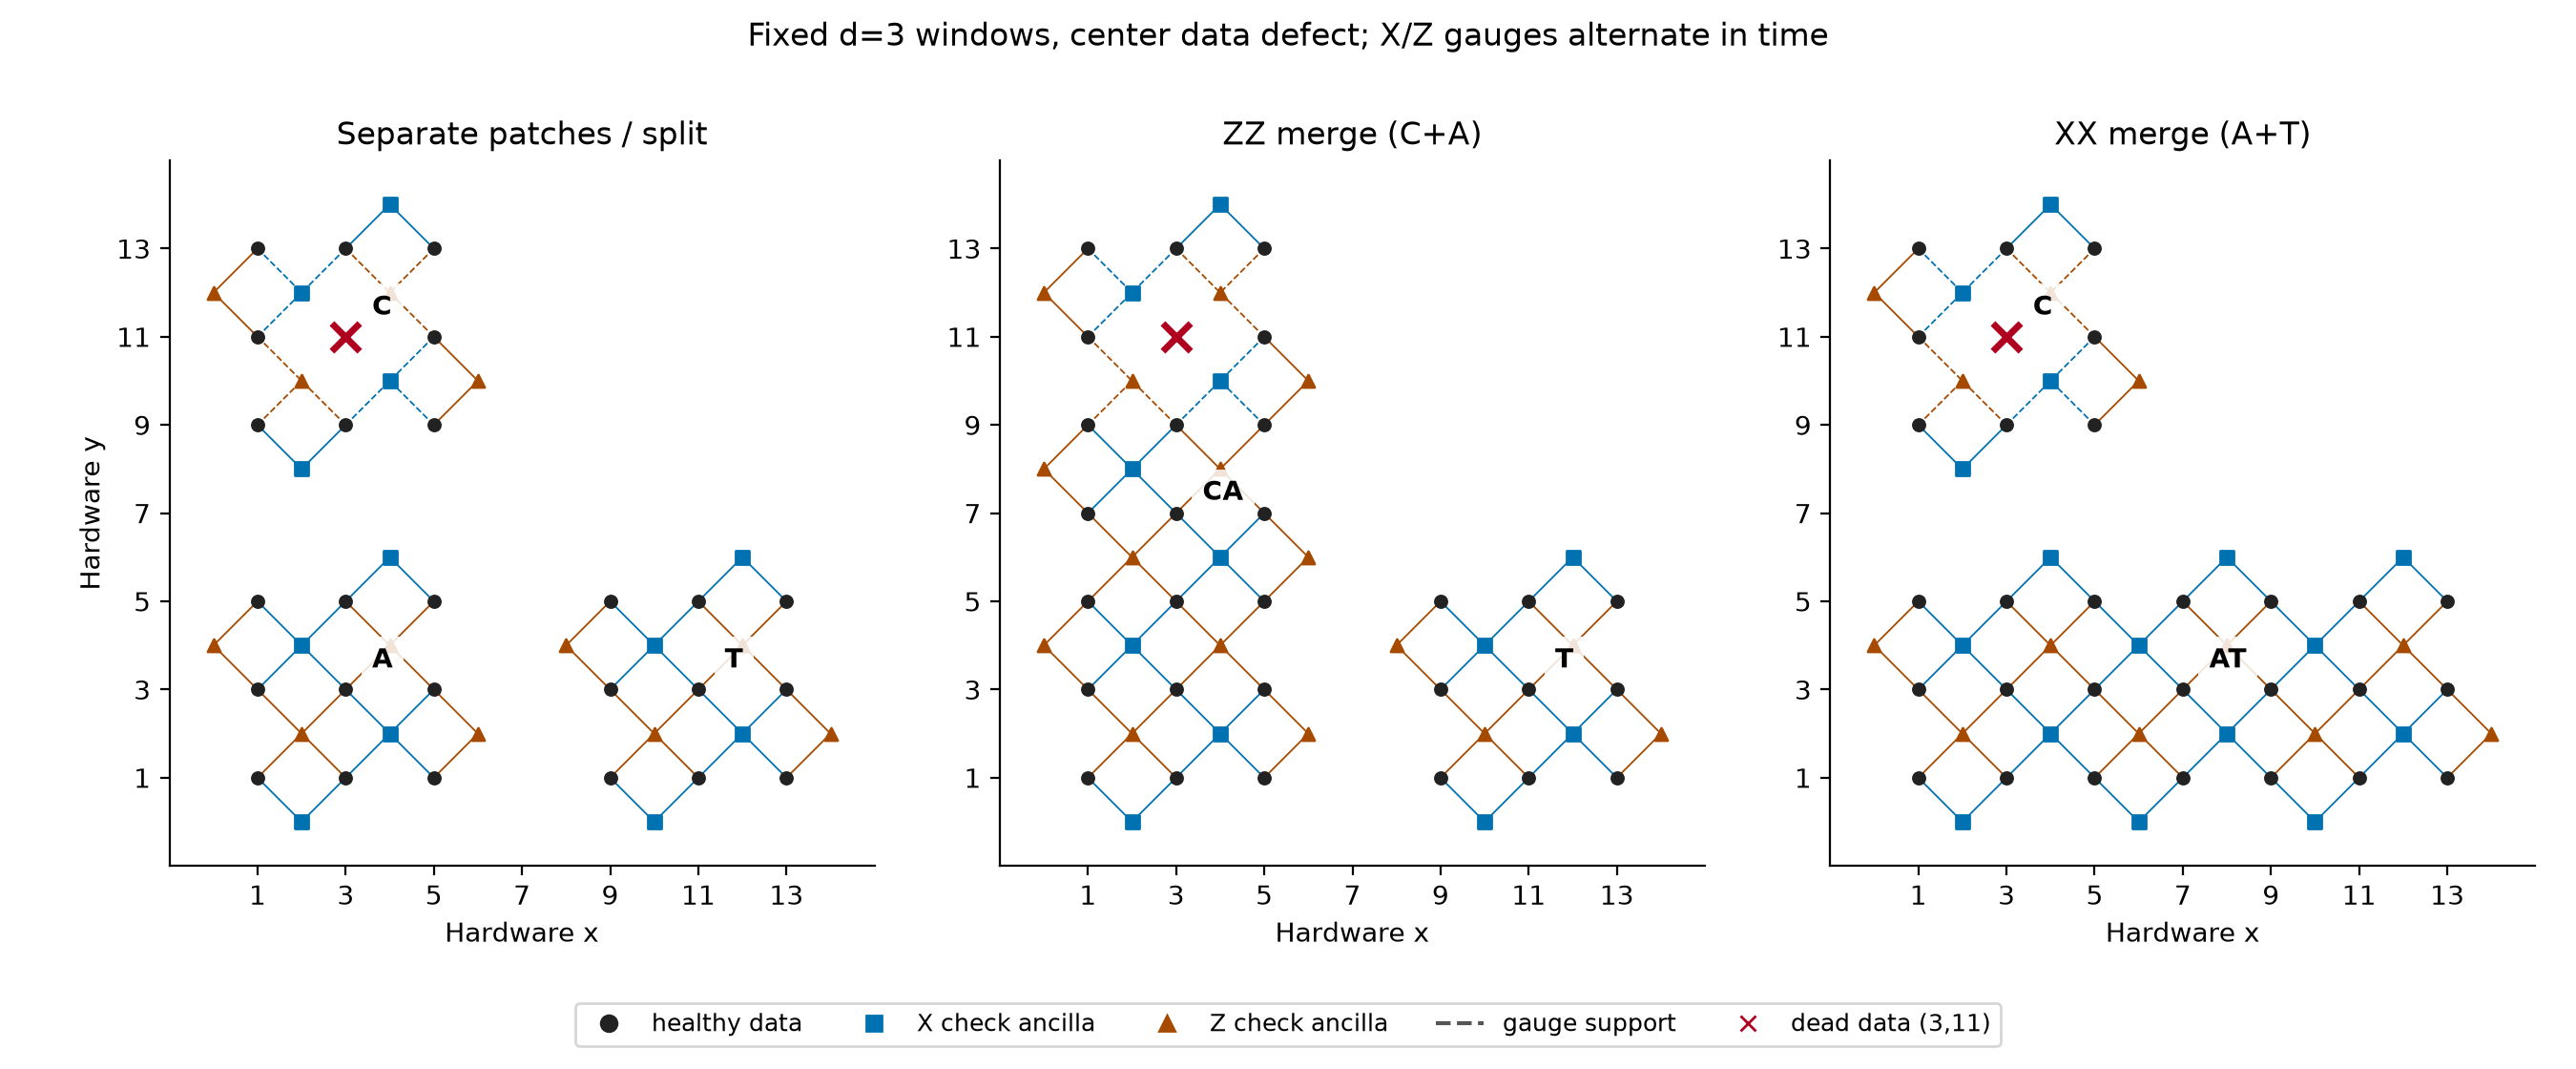

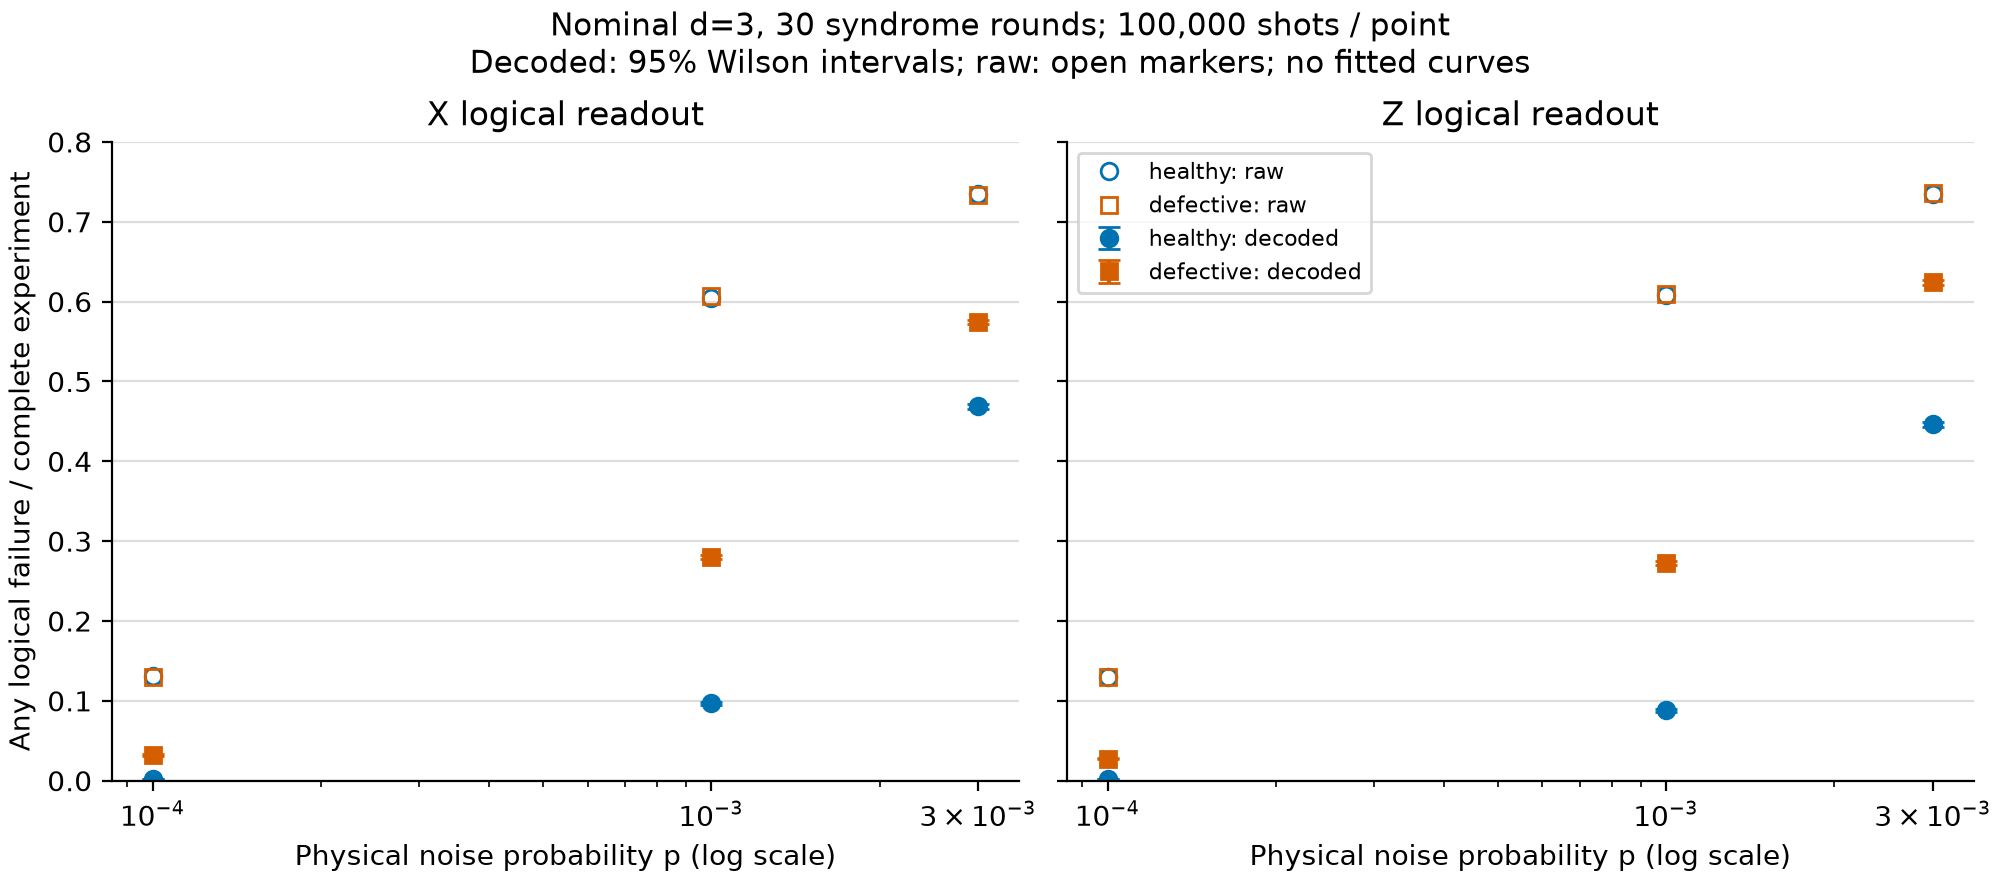

In [19]:
def run_existing_script(filename,*arguments):
    env = os.environ.copy()
    env['PYTHONIOENCODING'] = 'utf-8'
    result = subprocess.run([sys.executable,str(EXPERIMENT_DIR/filename),*map(str,arguments)],
                            cwd=EXPERIMENT_DIR,env=env,capture_output=True,text=True,
                            encoding='utf-8',errors='replace')
    if result.returncode:
        raise RuntimeError(result.stdout+'\n'+result.stderr)
    return result.stdout

print(run_existing_script('plot_results.py','--results',RUN_DIR))
display(Image(filename=str(RUN_DIR/'figures'/'patch_layouts.png')))
display(Image(filename=str(RUN_DIR/'figures'/'logical_error_rates.png')))


## 12. 生成独立 TQEC k=1 参考

调用现有 `tqec_reference.py`，k=1 对应 d=3。使用子进程运行现有入口，保留 Windows multiprocessing 的 `__main__` 保护。参考 X/Z 无噪声应通过、graphlike 上界应为 3。

参考布局、时序及噪声与主实验不同，所以不放入缺陷/健康配对的 LER 曲线。


In [20]:
print(run_existing_script('tqec_reference.py','--out',RUN_DIR/'tqec_reference'))
tqec_validation = json.loads((RUN_DIR/'tqec_reference'/'validation.json').read_text(encoding='utf-8'))
show_table([{'基':basis,'k':value['k'],'TICK':value['ticks'],
            'graphlike上界':value['graphlike_upper_bound'],'observable翻转':value['observable_flips']}
            for basis,value in tqec_validation.items()])


Compiling TQEC X, k=1...
Compiling TQEC Z, k=1...
{'X': {'k': 1, 'nominal_distance': 3, 'graphlike_upper_bound': 3, 'qubits': 81, 'ticks': 83, 'observables': 2, 'shots': 1024, 'detector_events': 0, 'observable_flips': 0, 'role': 'separate ideal-chip structural reference, different schedule and noise; not paired LER control'}, 'Z': {'k': 1, 'nominal_distance': 3, 'graphlike_upper_bound': 3, 'qubits': 81, 'ticks': 83, 'observables': 2, 'shots': 1024, 'detector_events': 0, 'observable_flips': 0, 'role': 'separate ideal-chip structural reference, different schedule and noise; not paired LER control'}}



基,k,TICK,graphlike上界,observable翻转
X,1,83,3,0
Z,1,83,3,0


## 13. 从导出的文件重新复核

调用已有 `verify_outputs.py` 重读 Stim 和 metadata，而不只检查内存中的对象。确认局域边、时隙、无噪声结果、Choi flows、采样计数和区间一致。通过后保存本 Notebook 的运行摘要。


In [21]:
run_existing_script('verify_outputs.py','--results',RUN_DIR)
delivery = json.loads((RUN_DIR/'delivery_validation.json').read_text(encoding='utf-8'))
assert delivery['total_shots'] == 12*SHOTS
print('交付文件复核通过；总采样:',delivery['total_shots'])
show_table([{'线路':key,'DEM距离':value['distance'],'无噪声shots':value['noiseless_shots'],
            'native flows':value['native_flows'],'局域CX':value['local_edges']}
            for key,value in delivery['circuits'].items()])
NOTEBOOK_COMPLETION = {'run_directory':str(RUN_DIR),'shots':delivery['total_shots'],
                       'distances':{key:result['distance'] for key,result in DISTANCES.items()},
                       'experiment_pipeline_completed':True}
write_json(RUN_DIR/'notebook_completion.json',NOTEBOOK_COMPLETION)
print('主缺陷 Stim:',RUN_DIR/'defective'/'cnot_X.stim')
print('主缺陷 Stim:',RUN_DIR/'defective'/'cnot_Z.stim')


交付文件复核通过；总采样: 1200000


线路,DEM距离,无噪声shots,native flows,局域CX
healthy_X,3,1024,True,True
healthy_Z,3,1024,True,True
defective_X,2,1024,True,True
defective_Z,2,1024,True,True


主缺陷 Stim: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\notebook_runs\20261015T062709_817016Z\defective\cnot_X.stim
主缺陷 Stim: D:\postgraduate\FTQC\科研内容\defective and logical operator\logical operator on defective chip - GPT工作\实验代码\defective_cnot_d3\notebook_runs\20261015T062709_817016Z\defective\cnot_Z.stim


## 14. 一个练习：为什么不能忽略 hyperedges？

以下两个故障都触发 D0、D1、D2，但只有第二个翻转 L0。组合后 detector syndrome 抵消，逻辑翻转保留。先预测最小故障数，再运行下一单元验证。


In [22]:
example = stim.DetectorErrorModel('error(0.1) D0 D1 D2\nerror(0.1) D0 D1 D2 L0')
answer = low_weight_distance(example)
assert answer['distance'] == 2
print('答案：完整 DEM 机制模型中的距离 =',answer['distance'])
for fault in answer['witness']:
    print(fault['error'])


答案：完整 DEM 机制模型中的距离 = 2
error(0.1) D0 D1 D2
error(0.1) D0 D1 D2 L0


## 后续实验与边界缺陷

- 先修改 `SHOTS` 或正概率 p 点，Restart Kernel and Run All，比较解码率及区间；不同运行写入不同目录。
- 普通边界随机 Pauli 错误已包含在噪声模型中。永久边界/corner 数据缺陷属于后续设计；当前 `build_patches` 对非指定位置明确拒绝。不要只删除比特后沿用旧 selectors。
- 扩展缺陷类型时重新验证边界重构、bare logical、merge/split 相容性、四个带符号 flows、静态/线路距离和 decoder 兼容性。
- 本例使用指定 X/Z 读出及普通 MWPM；没有进行阈值拟合、optimal decoder 比较或通用信道距离认证。

来源：[SnL 论文](https://arxiv.org/html/2412.11504v1)、[SnL 源码](https://github.com/amazon-science/snakes_and_ladders_adapting_the_surface_code_to_defects)、[TQEC CNOT](https://tqec.github.io/tqec/auto_examples/cnot.html)。具体提交、许可、作图流程来源和估计量说明见 [README](README.md)。
